In [46]:
import polars as pl
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

df = pl.read_csv("open-meteo-47.70N122.08W14m.csv", skip_rows=3)

grouped = (
    df.drop_nulls(subset=["time", "precipitation (mm)"])
    .with_columns(pl.col("time").str.slice(0, 4).alias("year"))
    .group_by("year", maintain_order=True)
    .agg(pl.col("precipitation (mm)"))
)

groups = grouped["precipitation (mm)"].to_list()
f_stat, p_value = stats.f_oneway(*groups)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value:     {p_value:.4e}")



F-statistic: 25.6378
P-value:     1.4977e-216


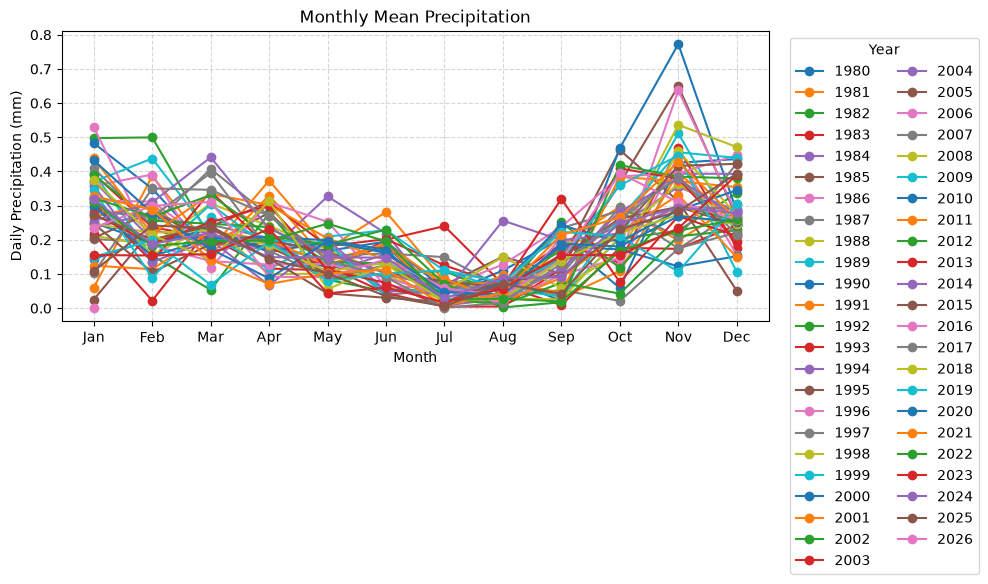

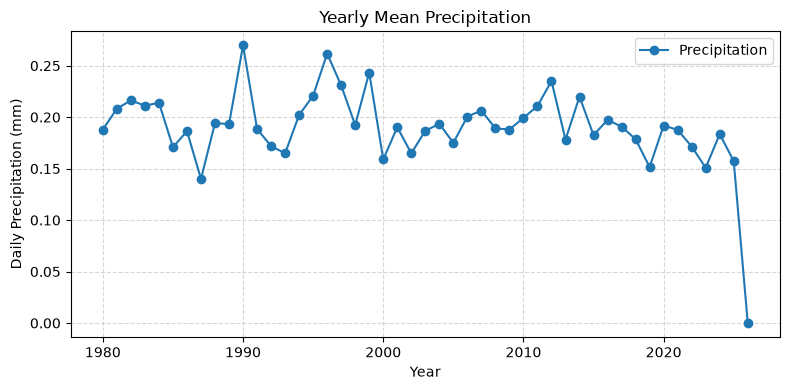

In [50]:
import matplotlib.pyplot as plt
import calendar

monthlyAvg = (
    df.with_columns(
        pl.col("time").str.to_datetime()
    )
    .group_by(
        pl.col("time").dt.year().alias("year"),
        pl.col("time").dt.month().alias("month"),
    )
    .agg(pl.col("precipitation (mm)").mean().alias("monthly_avg"))
    .sort(["year", "month"])
)

fig, ax = plt.subplots(figsize=(10, 5))

# maintain_order=True preserves the sorted year order
for (year,), year_df in monthlyAvg.group_by("year", maintain_order=True):
    ax.plot(
        year_df["month"],
        year_df["monthly_avg"],
        marker="o",
        label=str(year),
    )

# 4. Format the X-axis with month names
ax.set_xticks(range(1, 13))
ax.set_xticklabels(calendar.month_abbr[1:])
ax.set_xlabel("Month")
ax.set_ylabel("Daily Precipitation (mm)")
ax.set_title("Monthly Mean Precipitation")
ax.legend(title="Year")
ax.grid(True, linestyle="--", alpha=0.5)
plt.legend(
    title='Year',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=2
)
plt.tight_layout()
plt.show()


yearly_avg = (
        df.with_columns(
        pl.col("time").str.to_datetime()
    )
    .group_by(pl.col("time").dt.year().alias("year"))
    .agg(pl.col("precipitation (mm)").mean().alias("yearly_average"))
    .sort("year")
)


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(yearlyAvg["year"], yearly_avg["yearly_average"], marker="o", label="Precipitation")

ax.set_title("Yearly Mean Precipitation")
ax.set_xlabel("Year")
ax.set_ylabel("Daily Precipitation (mm)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()